# EDA - HVDROPDB (v3)

**Fuente:** Mendeley Data, dataset `xw5xc7xrmp`, version 3. DOI `10.17632/xw5xc7xrmp`. Autor: Ranjana Agrawal.

**Origen clinico:** cribado de ROP en PBMA's H.V. Desai Eye Hospital, Pune, India. Imagenes de los sistemas RetCam y Neo.

**Contenido:** dos subsets distintos:
1. **Segmentacion** (el que usamos para Fase 1): 50 imagenes x 2 camaras (Neo, RetCam) x 3 estructuras (vasos, disco optico, cresta) = 300 pares imagen/mascara, sin metadatos clinicos.
2. **Clasificacion** (fuera del scope del manifiesto unificado): 189 imagenes Normal/ROP, tampoco con metadatos clinicos ni patient ID - no puede alimentar la Cross-Attention (no hay vector clinico que acompane). Se documenta aqui pero no se extrae por defecto en `extract_archives.py`.

Este notebook explora el dataset **crudo**.

In [1]:
import zipfile
import rarfile
from pathlib import Path
from collections import Counter

import matplotlib.pyplot as plt
from PIL import Image

ROOT = Path.cwd().resolve().parent.parent  # system/eda/ -> ROP_paper/
RAW_DIR = ROOT / "datasets" / "HVDROPDB_Original"
EXTRACTED_SEG = ROOT / "datasets" / "extracted" / "HVDROPDB" / "HVDROPDB_RetCam_Neo_Segmentation"

plt.rcParams["figure.figsize"] = (8, 4)

## Estructura del subset de Segmentacion y verificacion del pareo imagen/mascara

In [2]:
rows = []
for structure_dir in sorted(EXTRACTED_SEG.glob("HVDROPDB-*")):
    structure = structure_dir.name.replace("HVDROPDB-", "")
    for images_dir in sorted(structure_dir.glob("*_images")):
        camera = "Neo" if images_dir.name.startswith("Neo") else "RetCam"
        masks_dir = images_dir.parent / images_dir.name.replace("_images", "_masks")
        imgs = {p.name for p in images_dir.glob("*.png")}
        masks = {p.name for p in masks_dir.glob("*.png")} if masks_dir.exists() else set()
        rows.append({
            "estructura": structure, "camara": camera,
            "n_imagenes": len(imgs), "n_mascaras": len(masks),
            "pareo_completo": imgs == masks,
        })
import pandas as pd
pd.DataFrame(rows)

,estructura,camara,n_imagenes,n_mascaras,pareo_completo
0,BV,Neo,50,50,True
1,BV,RetCam,50,50,True
2,OD,Neo,50,50,True
3,OD,RetCam,50,50,True
4,RIDGE,Neo,50,50,True
5,RIDGE,RetCam,50,50,True


## Muestra visual: imagen + mascara por estructura

*Nota: la celda de abajo originalmente afirmaba, en base a comparar solo el indice `1.png` y solo la camara Neo, que las 3 estructuras eran "colecciones independientes, no el mismo set de 50 fotos anotado 3 veces". Esa verificacion era incompleta (un solo indice, una sola camara) y la conclusion general es **incorrecta** - ver la celda de hash exhaustivo mas abajo, que la corrige con datos reales.*

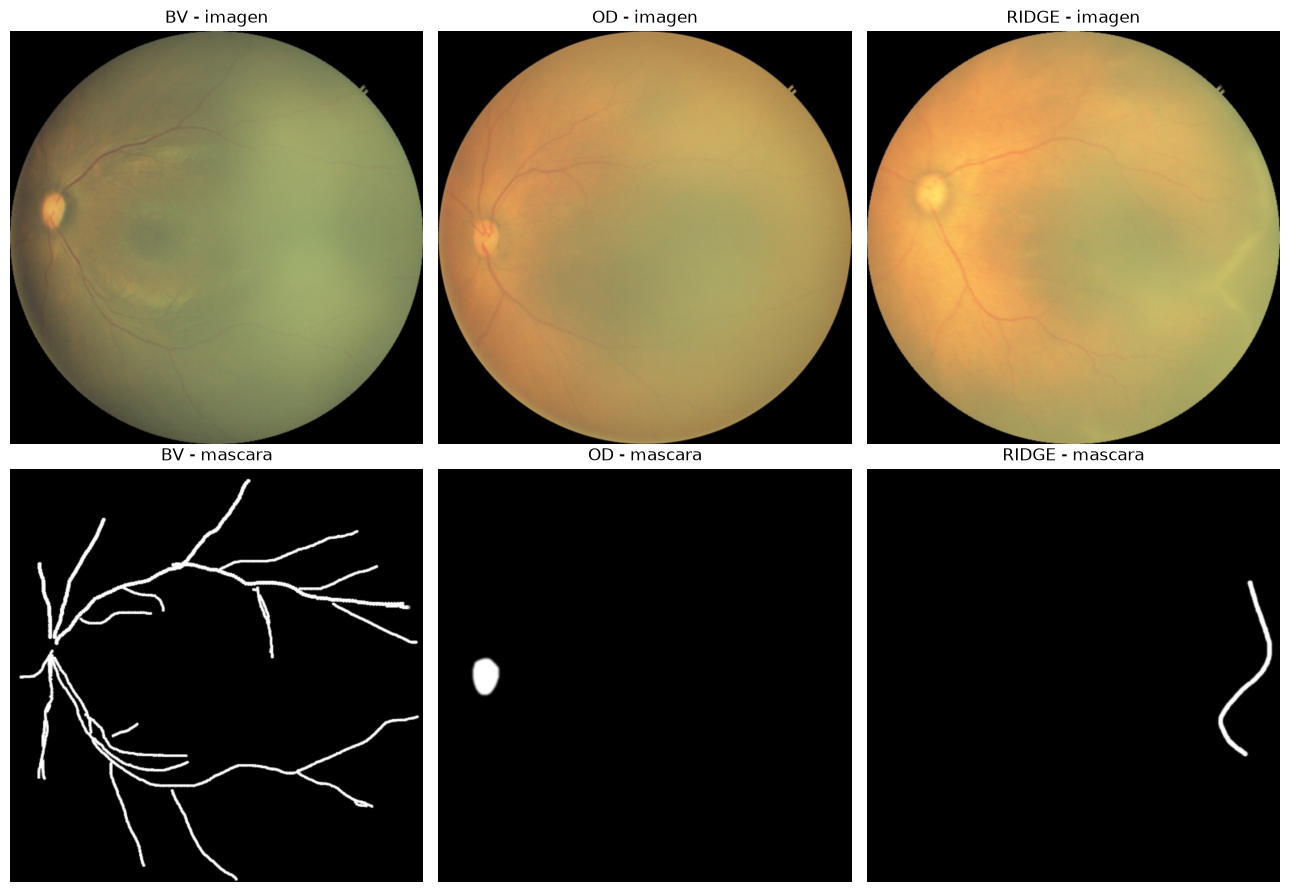

In [3]:
structures = [("BV", "Neo_Vessels"), ("OD", "Neo_OpticDisc"), ("RIDGE", "Neo_Ridge")]
fig, axes = plt.subplots(2, 3, figsize=(13, 9))
for col, (code, prefix) in enumerate(structures):
    img_path = EXTRACTED_SEG / f"HVDROPDB-{code}" / f"{prefix}_images" / "1.png"
    mask_path = EXTRACTED_SEG / f"HVDROPDB-{code}" / f"{prefix}_masks" / "1.png"
    axes[0, col].imshow(Image.open(img_path))
    axes[0, col].set_title(f"{code} - imagen")
    axes[0, col].axis("off")
    axes[1, col].imshow(Image.open(mask_path), cmap="gray")
    axes[1, col].set_title(f"{code} - mascara")
    axes[1, col].axis("off")
plt.tight_layout()
plt.show()

## Correccion: hash exhaustivo de las 300 imagenes (no solo el indice 1, no solo Neo)

La celda anterior solo comparo `1.png` entre `Neo_Vessels`, `Neo_OpticDisc` y `Neo_Ridge` - y para Neo, el solape real esta entre `BV` y `RIDGE` (no entre `BV` y `OD`), asi que ese indice en particular no lo detecto. Tampoco se habia probado la camara RetCam. Hash MD5 de las 300 imagenes (no las mascaras) contra todas las demas:

In [4]:
import hashlib
from collections import defaultdict

def md5(p):
    return hashlib.md5(p.read_bytes()).hexdigest()

hash_to_keys = defaultdict(list)
for structure_dir in sorted(EXTRACTED_SEG.glob("HVDROPDB-*")):
    structure = structure_dir.name.replace("HVDROPDB-", "")
    for images_dir in sorted(structure_dir.glob("*_images")):
        camera = "Neo" if images_dir.name.startswith("Neo") else "RetCam"
        for p in images_dir.glob("*.png"):
            hash_to_keys[md5(p)].append((structure, camera, p.name))

n_total = sum(len(v) for v in hash_to_keys.values())
n_unique = len(hash_to_keys)
dupe_groups = {h: v for h, v in hash_to_keys.items() if len(v) > 1}
print("imagenes totales:", n_total, " | hashes unicos (fotos fuente distintas):", n_unique)
print("grupos con mas de 1 ocurrencia (misma foto en >1 carpeta de estructura):", len(dupe_groups))
print("filas 'extra' que comparten foto con otra:", n_total - n_unique)

combo_counts = Counter()
for keys in dupe_groups.values():
    combo = tuple(sorted({(s, c) for s, c, _ in keys}))
    combo_counts[combo] += 1
print("\nDesglose por combinacion de estructura/camara que comparte foto:")
for combo, n in combo_counts.most_common():
    print(" ", n, combo)

imagenes totales: 300  | hashes unicos (fotos fuente distintas): 262
grupos con mas de 1 ocurrencia (misma foto en >1 carpeta de estructura): 38
filas 'extra' que comparten foto con otra: 38

Desglose por combinacion de estructura/camara que comparte foto:
  25 (('BV', 'RetCam'), ('OD', 'RetCam'))
  10 (('BV', 'Neo'), ('RIDGE', 'Neo'))
  3 (('BV', 'RetCam'), ('RIDGE', 'RetCam'))


## Subset de Clasificacion (fuera de scope) - solo para documentar que existe

No se extrae por defecto. Lo leemos directo del `.rar` original (via `rarfile`, solo listado, sin extraer) para dejar registro de su estructura.

In [5]:
rf = rarfile.RarFile(RAW_DIR / "HVDROPDB_RetCam_Neo_Classification.rar")
names = [n for n in rf.namelist() if n.endswith(".png")]
dirs = Counter(n.split("/")[0] for n in names)
print("Total imagenes:", len(names))
for k, v in dirs.items():
    print(" ", k, v)
print("\nSin patient ID, sin GA/BW/PMA - no se puede unir con ningun vector clinico.")

Total imagenes: 185
  RetCam_Normal 50
  RetCam_ROP 50
  Neo_Normal 50
  Neo_ROP 35

Sin patient ID, sin GA/BW/PMA - no se puede unir con ningun vector clinico.


## Resumen de hallazgos - HVDROPDB

- **Subset de Segmentacion: 300 pares imagen/mascara** (50 x 2 camaras x 3 estructuras), pareo 1:1 verificado sin huerfanos. Es poco volumen para preentrenar un backbone desde cero - se recomienda partir de pesos ImageNet y usar esto solo para el fine-tuning de Fase 1.
- **Corregido:** las 3 estructuras (vasos, disco optico, cresta) NO son colecciones completamente independientes. Hash MD5 exhaustivo de las 300 imagenes (no solo el indice 1, no solo Neo) encontro que **262 fotos fuente distintas** explican las 300 filas - 38 fotos (12.7%) se reciclan entre dos carpetas de estructura (con una mascara distinta cada vez): 25 `BV/RetCam<->OD/RetCam`, 10 `BV/Neo<->RIDGE/Neo`, 3 `BV/RetCam<->RIDGE/RetCam`. Ninguna foto aparece en las 3 estructuras a la vez, y `OD`/`RIDGE` nunca comparten foto entre si. Esto motivo la decision de split por hash de imagen (ver abajo).
- **Subset de Clasificacion (189 imagenes Normal/ROP) deliberadamente fuera del manifiesto**: no trae patient ID ni metadatos clinicos, no puede alimentar el vector de Cross-Attention. Queda documentado como posible tarea auxiliar binaria de Fase 1 si se decide usarlo mas adelante.
- Sin metadatos clinicos en ningun subset - esta fuente nunca entra a las tareas de Estadio/Plus/AP-ROP, solo a Fase 1 (pretraining visual).

## Estrategia de split confirmada y verificacion contra `clean_hvdropdb.py` / `split_hvdropdb.py` ya ejecutados

**Decision (ver README.md S2 y S5):** HVDROPDB no participa del Group K-Fold clinico (no tiene `patient_id`, es una etapa auxiliar de Fase 1, no el resultado reportado en la tesis). Usa un **split unico** train/val (no K-fold), agrupado por `image_hash` en vez de paciente - el identificador de identidad real disponible aqui, dado el hallazgo de las 38 fotos recicladas entre estructuras.

`clean_hvdropdb.py` construye `datasets/clean/HVDROPDB.parquet` (`pair_id`, `structure`, `camera`, `image_path`, `mask_path`, `image_hash`). `split_hvdropdb.py` (script separado, por disenio - ver su docstring) agrupa por `image_hash` y asigna `split` train/val (80/20, semilla fija) sin tocar el resto de columnas. Esta celda carga el resultado real y verifica que ninguna foto quedo partida entre ambos splits.

In [6]:
clean = pd.read_parquet(ROOT / "datasets" / "clean" / "HVDROPDB.parquet")

print("filas:", len(clean), " | fotos fuente (hash) distintas:", clean["image_hash"].nunique())
print(clean["split"].value_counts())
print()

base = ROOT / "datasets" / "extracted"
print("image_path faltantes:", sum(1 for p in clean["image_path"] if not (base / p).exists()))
print("mask_path faltantes:", sum(1 for p in clean["mask_path"] if not (base / p).exists()))

split_per_hash = clean.groupby("image_hash")["split"].nunique()
print("fotos (hash) con split inconsistente entre sus filas:", int((split_per_hash > 1).sum()))

print()
print(clean.groupby(["structure", "camera", "split"]).size().unstack(fill_value=0))

filas: 300  | fotos fuente (hash) distintas: 262
split
train    240
val       60
Name: count, dtype: int64

image_path faltantes: 0
mask_path faltantes: 0
fotos (hash) con split inconsistente entre sus filas: 0

split             train  val
structure camera            
BV        Neo        41    9
          RetCam     41    9
OD        Neo        43    7
          RetCam     39   11
RIDGE     Neo        43    7
          RetCam     33   17
